In [1]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="pSMXmtzQ0jVkLJiYgev0")
project = rf.workspace("helmet-and-number-plate-detection-project").project("helmet-and-number-plate-detection-for-motorbike-safety-iityz")
version = project.version(3)
dataset = version.download("yolov8")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 38.6 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Helmet-and-Number-Plate-Detection-for-Motorbike-Safety-3 in yolov8:: 100%|██████████| 40586/40586 [00:06<00:00, 6100.20it/s]


In [2]:
!pip install -q ultralytics easyocr seaborn

import yaml

with open(f"{dataset.location}/data.yaml", "r") as f:
    data_cfg = yaml.safe_load(f)

print("Dataset Classes:", data_cfg["names"])

Dataset Classes: ['bike', 'helmet', 'no-helmet', 'number-plate']


In [3]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

results = model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=15,
    imgsz=640,
    batch=32,
    name="traffic_violation_detector"
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Helmet-and-Number-Plate-Detection-for-Motorbike-Safety-3/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, f

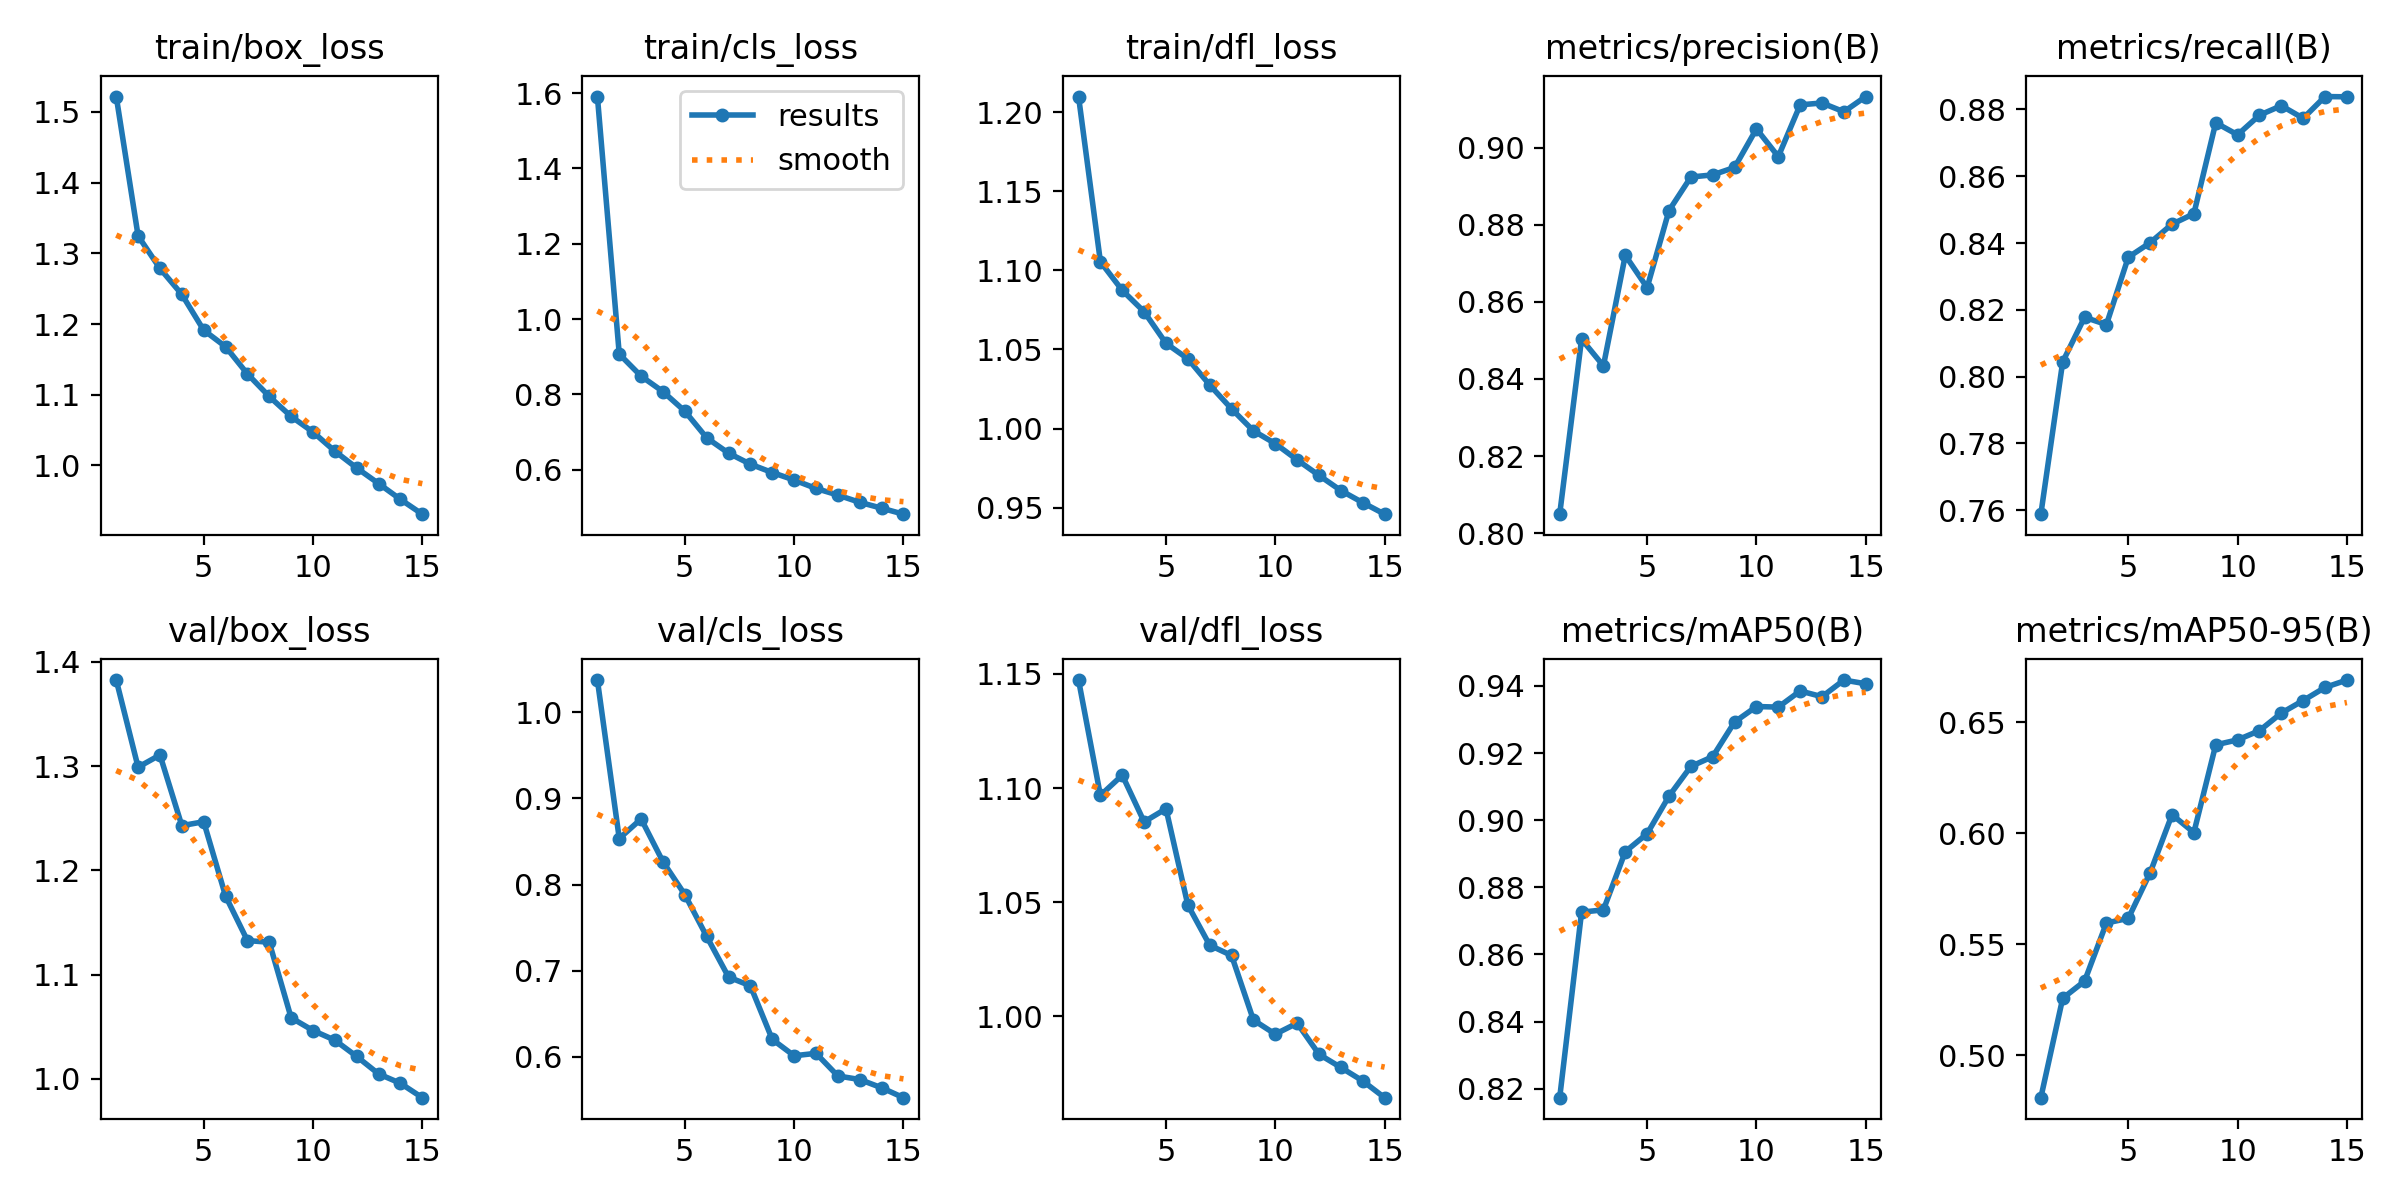

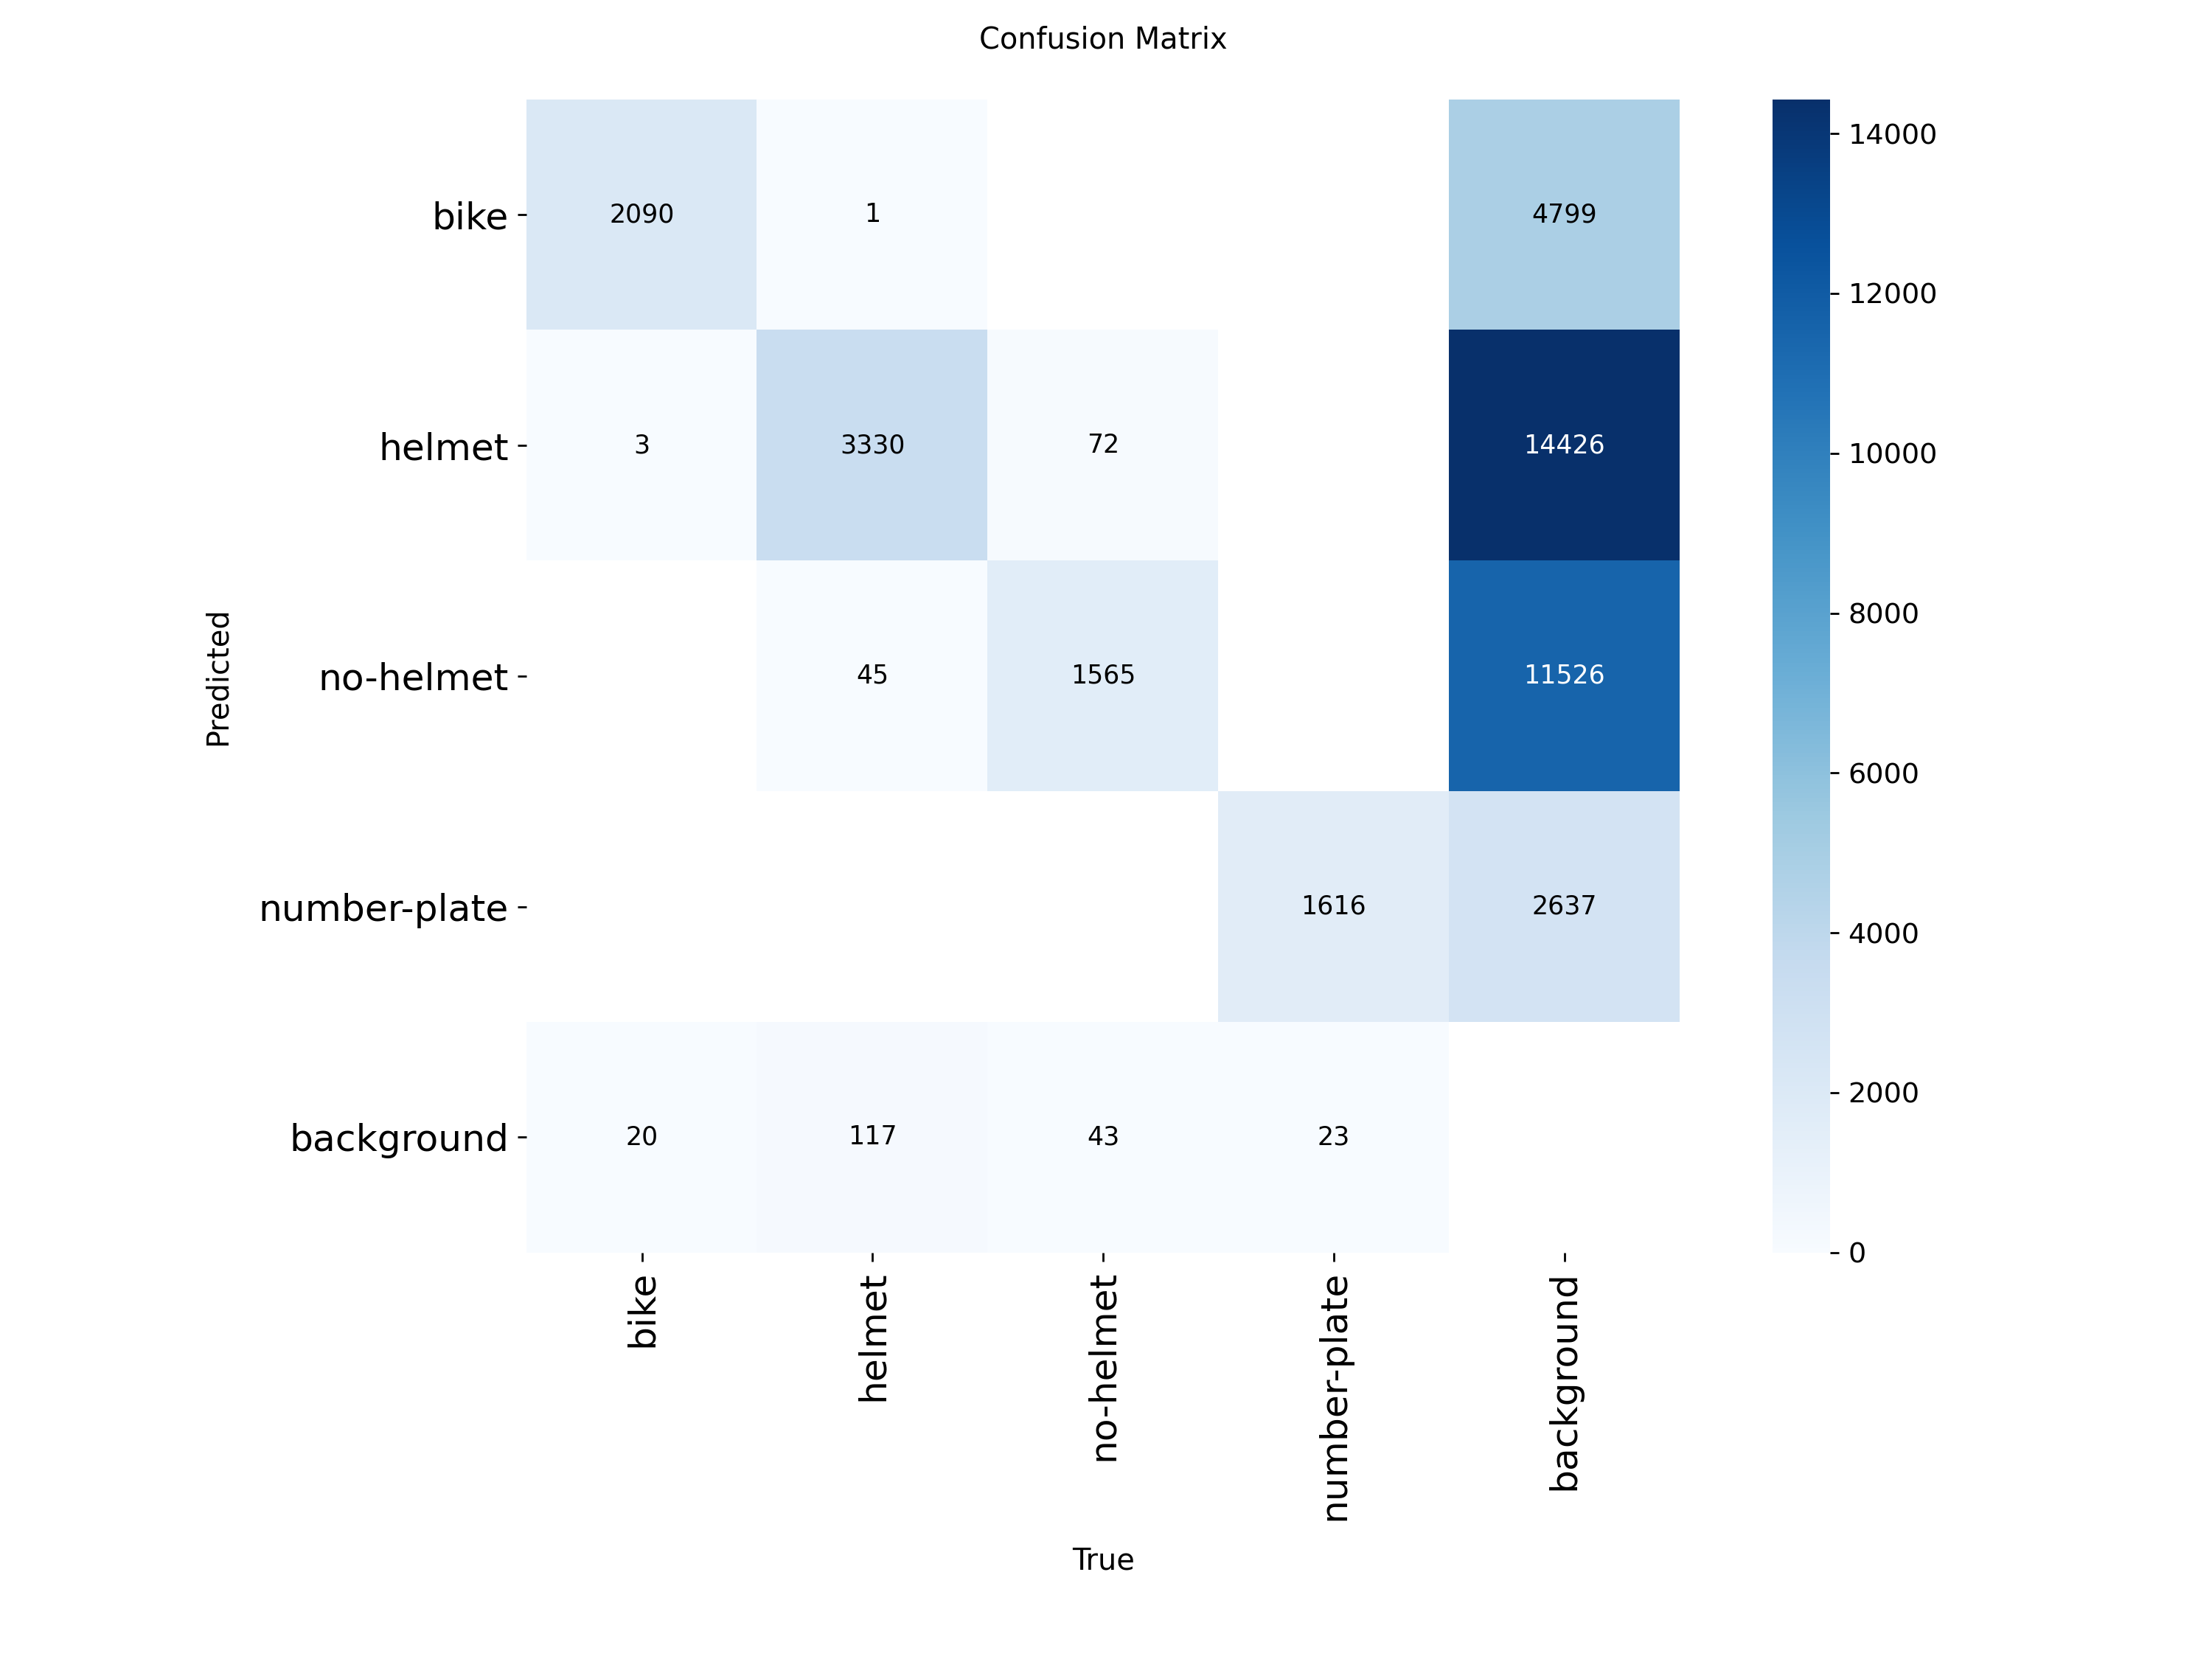

In [4]:
from IPython.display import Image, display

display(Image(filename="runs/detect/traffic_violation_detector/results.png", width=850))
display(Image(filename="runs/detect/traffic_violation_detector/confusion_matrix.png", width=650))

In [5]:
import os
import glob
import cv2
import easyocr
import pandas as pd
from ultralytics import YOLO

best_model = YOLO("runs/detect/traffic_violation_detector/weights/best.pt")
ocr = easyocr.Reader(['en'], gpu=True)

image_files = (
    glob.glob(f"{dataset.location}/test/images/*.*") +
    glob.glob(f"{dataset.location}/valid/images/*.*")
)
print(f"Running violation & OCR analytics on {len(image_files)} images...")

os.makedirs("evidence_crops", exist_ok=True)
rows = []

def is_inside_or_overlapping(parent_box, child_box, pad_top=40):
    px1, py1, px2, py2 = parent_box[0], max(0, parent_box[1] - pad_top), parent_box[2], parent_box[3]
    cx_mid = (child_box[0] + child_box[2]) / 2
    cy_mid = (child_box[1] + child_box[3]) / 2
    return (px1 <= cx_mid <= px2) and (py1 <= cy_mid <= py2)

for idx, img_path in enumerate(image_files):
    img = cv2.imread(img_path)
    if img is None:
        continue

    pred = best_model.predict(img, conf=0.35, verbose=False)[0]
    names = best_model.names

    bikes, helmets, no_helmets, plates = [], [], [], []

    for box in pred.boxes:
        cls_label = names[int(box.cls[0])]
        x1, y1, x2, y2 = map(int, box.xyxy[0])
        conf = round(float(box.conf[0]), 3)

        if cls_label == "bike":
            bikes.append((x1, y1, x2, y2, conf))
        elif cls_label == "helmet":
            helmets.append((x1, y1, x2, y2, conf))
        elif cls_label == "no-helmet":
            no_helmets.append((x1, y1, x2, y2, conf))
        elif cls_label == "number-plate":
            plates.append((x1, y1, x2, y2, conf))

    for v_idx, nh_box in enumerate(no_helmets):
        nx1, ny1, nx2, ny2, nconf = nh_box
        matched_bike = None
        for b_box in bikes:
            if is_inside_or_overlapping(b_box, nh_box):
                matched_bike = b_box
                break

        matched_plate = None
        if matched_bike is not None:
            for p_box in plates:
                if is_inside_or_overlapping(matched_bike, p_box, pad_top=0):
                    matched_plate = p_box
                    break
        else:
            nx_mid = (nx1 + nx2) / 2
            min_dist = 1e9
            for p_box in plates:
                px_mid = (p_box[0] + p_box[2]) / 2
                if p_box[1] >= ny1 and abs(px_mid - nx_mid) < 180:
                    dist = ((px_mid - nx_mid) ** 2 + (p_box[1] - ny2) ** 2) ** 0.5
                    if dist < min_dist:
                        min_dist = dist
                        matched_plate = p_box

        plate_text = "UNREADABLE"
        plate_conf = 0.0
        if matched_plate is not None:
            px1, py1, px2, py2, plate_conf = matched_plate
            plate_crop = img[max(0, py1):py2, max(0, px1):px2]
            if plate_crop.size > 0:
                gray = cv2.cvtColor(plate_crop, cv2.COLOR_BGR2GRAY)
                raw_text = ocr.readtext(gray, detail=0)
                clean_text = "".join([c for c in "".join(raw_text) if c.isalnum()]).upper()
                if len(clean_text) >= 4:
                    plate_text = clean_text

        if matched_bike is not None:
            bx1, by1, bx2, by2, _ = matched_bike
            evidence = img[max(0, by1 - 25):by2, max(0, bx1):bx2]
        else:
            evidence = img[max(0, ny1 - 20):min(img.shape[0], ny2 + 220), max(0, nx1 - 80):min(img.shape[1], nx2 + 80)]

        crop_filename = f"evidence_crops/viol_{idx}_{v_idx}.jpg"
        if evidence.size > 0:
            cv2.imwrite(crop_filename, evidence)

        rows.append({
            "Image_File": os.path.basename(img_path),
            "Bikes_In_Frame": len(bikes),
            "Compliant_Helmets": len(helmets),
            "Violators_In_Frame": len(no_helmets),
            "Bike_Box_Linked": matched_bike is not None,
            "Violation_Confidence": nconf,
            "Plate_Box_Found": matched_plate is not None,
            "Plate_Confidence": plate_conf,
            "Extracted_Plate_Text": plate_text,
            "Evidence_Path": crop_filename
        })

df = pd.DataFrame(rows)
df.to_csv("violation_analytics_dataset.csv", index=False)

print(f"Total Violations Logged   : {len(df)}")
print(f"Linked to Parent Bike Box : {df['Bike_Box_Linked'].sum()}")
print(f"Readable Plates Extracted : {(df['Extracted_Plate_Text'] != 'UNREADABLE').sum()}")
display(df.head(15))

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% CompleteRunning violation & OCR analytics on 2545 images...
Total Violations Logged   : 2267
Linked to Parent Bike Box : 897
Readable Plates Extracted : 12


,Image_File,Bikes_In_Frame,Compliant_Helmets,Violators_In_Frame,Bike_Box_Linked,Violation_Confidence,Plate_Box_Found,Plate_Confidence,Extracted_Plate_Text,Evidence_Path
0,test6_mp4-0015_jpg.rf.8e43f3be5b88344e2fa70968...,0,6,4,False,0.782,False,0.000,UNREADABLE,evidence_crops/viol_1_0.jpg
1,test6_mp4-0015_jpg.rf.8e43f3be5b88344e2fa70968...,0,6,4,False,0.775,False,0.000,UNREADABLE,evidence_crops/viol_1_1.jpg
2,test6_mp4-0015_jpg.rf.8e43f3be5b88344e2fa70968...,0,6,4,False,0.739,False,0.000,UNREADABLE,evidence_crops/viol_1_2.jpg
3,test6_mp4-0015_jpg.rf.8e43f3be5b88344e2fa70968...,0,6,4,False,0.720,False,0.000,UNREADABLE,evidence_crops/viol_1_3.jpg
4,BikesHelmets291_png_jpg.rf.7f3107cc96b6c838330...,1,0,1,True,0.474,True,0.463,UNREADABLE,evidence_crops/viol_3_0.jpg
5,3783241-hd_1920_1080_25fps_050_jpg.rf.2dc4ad6e...,0,2,3,False,0.752,False,0.000,UNREADABLE,evidence_crops/viol_4_0.jpg
6,3783241-hd_1920_1080_25fps_050_jpg.rf.2dc4ad6e...,0,2,3,False,0.595,False,0.000,UNREADABLE,evidence_crops/viol_4_1.jpg
7,3783241-hd_1920_1080_25fps_050_jpg.rf.2dc4ad6e...,0,2,3,False,0.582,False,0.000,UNREADABLE,evidence_crops/viol_4_2.jpg
8,frame_15_693_jpg.rf.a6b1332ae5a043b0019d5f6e21...,3,3,1,True,0.821,True,0.838,UNREADABLE,evidence_crops/viol_7_0.jpg
9,frame_3_1569_jpg.rf.a84d4bf4938604c025e38783a7...,1,0,1,True,0.807,False,0.000,UNREADABLE,evidence_crops/viol_12_0.jpg


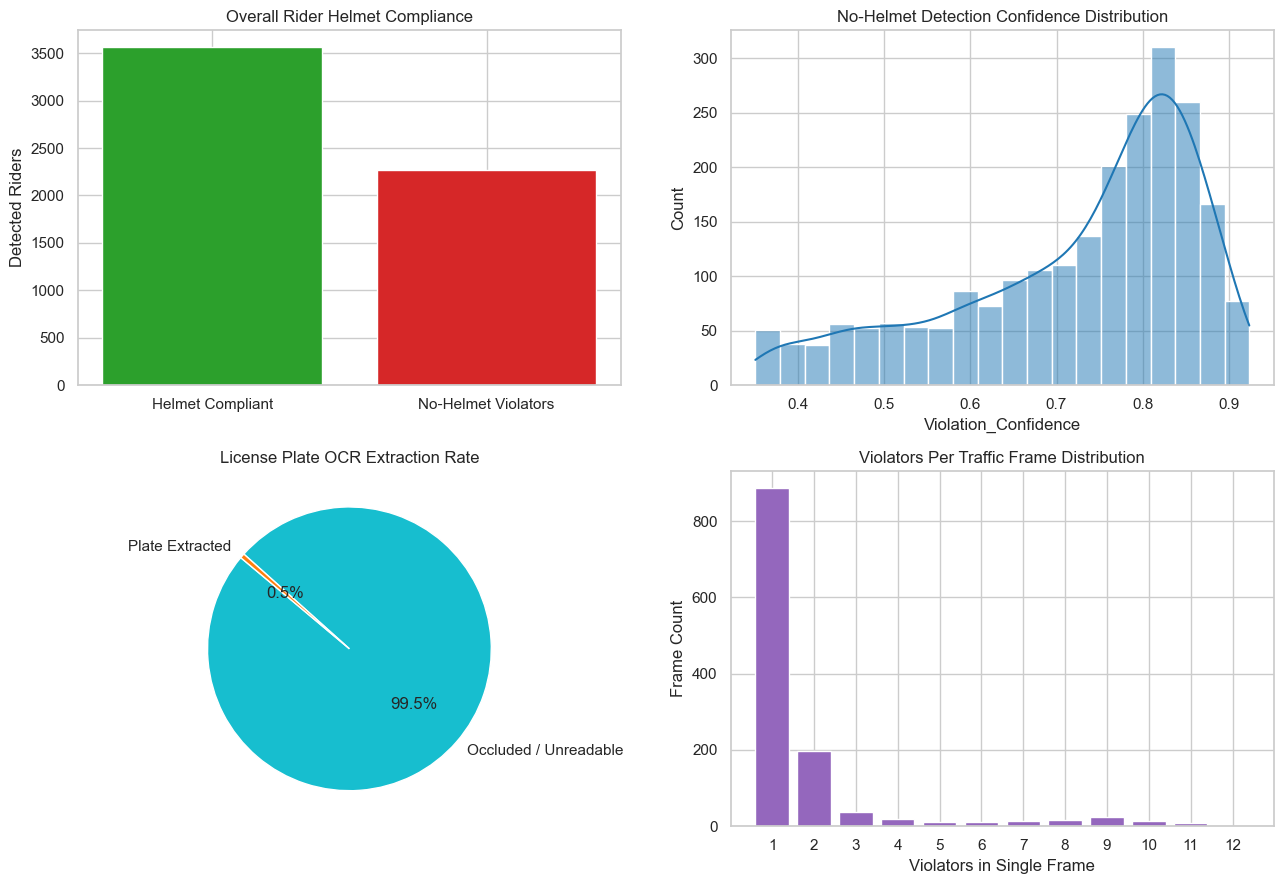

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

compliant_total = df["Compliant_Helmets"].sum()
violator_total = len(df)
axes[0, 0].bar(["Helmet Compliant", "No-Helmet Violators"], [compliant_total, violator_total], color=["#2ca02c", "#d62728"])
axes[0, 0].set_title("Overall Rider Helmet Compliance")
axes[0, 0].set_ylabel("Detected Riders")

sns.histplot(df["Violation_Confidence"], bins=20, kde=True, ax=axes[0, 1], color="#1f77b4")
axes[0, 1].set_title("No-Helmet Detection Confidence Distribution")

ocr_counts = df["Extracted_Plate_Text"].apply(lambda x: "Plate Extracted" if x != "UNREADABLE" else "Occluded / Unreadable").value_counts()
axes[1, 0].pie(ocr_counts, labels=ocr_counts.index, autopct="%1.1f%%", colors=["#17becf", "#ff7f0e"], startangle=140)
axes[1, 0].set_title("License Plate OCR Extraction Rate")

per_frame = df.groupby("Image_File")["Violators_In_Frame"].first().value_counts().sort_index()
axes[1, 1].bar(per_frame.index.astype(str), per_frame.values, color="#9467bd")
axes[1, 1].set_title("Violators Per Traffic Frame Distribution")
axes[1, 1].set_xlabel("Violators in Single Frame")
axes[1, 1].set_ylabel("Frame Count")

plt.tight_layout()
plt.savefig("final_traffic_analytics.png", dpi=250)
plt.show()

!zip -q -r project_outputs.zip runs/detect/traffic_violation_detector/weights/best.pt runs/detect/traffic_violation_detector/results.png runs/detect/traffic_violation_detector/confusion_matrix.png violation_analytics_dataset.csv final_traffic_analytics.png evidence_crops/

files.download("project_outputs.zip")